# Notebook 07 — Expected Loss

**Enterprise Credit Risk Modeling & Validation Framework**

This notebook computes **Expected Loss (EL)** at customer and portfolio level using the three trained models: the LR credit scorecard (PD), the two-stage LGD model, and the CCF linear regression (EAD).

$$EL = PD \times LGD \times EAD$$

**Inputs:**
- `data/processed/val.parquet` — validation set (434,406 loans, 2016)
- `models/pd/lr_params.json` — LR scorecard (calibrated PD, WoE tables)
- `models/lgd/lgd_models.joblib` — two-stage LGD model
- `models/ead/ead_model.joblib` — EAD / CCF linear regression

**Outputs:**
- `artifacts/expected_loss_customer.csv` — EL per loan
- `artifacts/expected_loss_portfolio.csv` — EL summary by risk class
- `artifacts/credit_policy.csv` — per-loan approval decisions
- `artifacts/el_policy_summary.csv` — before/after policy comparison
- `artifacts/policy_sensitivity.csv` — EL at denial rates 0–30%
- `artifacts/el_concentration.csv` — EL Pareto analysis

In [1]:
import sys, os, json
import warnings
warnings.filterwarnings('ignore')

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
if '' not in sys.path:
    sys.path.insert(0, '')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import joblib

from src.utils import setup_logging, set_plot_style, save_figure, PLOT_COLOR, ACCENT_COLOR
from src.preprocessing import apply_woe_encoding

setup_logging()
set_plot_style()

PROCESSED_DIR = 'data/processed'
MODELS_DIR    = 'models'
HURDLE_RATE   = 0.0215
OP_COST_RATE  = 0.02
RISK_CLASSES  = ['AA','A','AB','BB','B','BC','C','CD','DD','F']

print('Setup complete. Working directory:', os.getcwd())

Setup complete. Working directory: [project root]


---
## Load Validation Data and Trained Models

The validation set (2016 vintage, 434,406 loans) is the evaluation population for all
three models. Models are loaded in their cross-version serialisation formats to ensure
reproducibility across Python environments.

In [2]:
# ── Load validation set and all model artifacts ───────────────────────────
val = pd.read_parquet(f'{PROCESSED_DIR}/val.parquet', engine='fastparquet')
print(f'Validation set: {len(val):,} rows  |  default rate: {(val["default"]==0).mean():.2%}')

with open(f'{MODELS_DIR}/pd/lr_params.json') as f:
    lr_params = json.load(f)

woe_results = {}
for feat, meta in lr_params['woe_results'].items():
    df_woe = pd.DataFrame(meta['records'])
    for col in ['n_good','n_obs','n_bad']:
        if col in df_woe.columns:
            df_woe[col] = df_woe[col].astype('int32')
    for col in ['bad_rate','pct_good','pct_bad','woe','iv']:
        if col in df_woe.columns:
            df_woe[col] = df_woe[col].astype(float)
    woe_results[feat] = (df_woe, float(meta.get('iv', 0)), meta.get('bin_edges'))

LR_CONST       = float(lr_params['const'])
LR_COEFS       = np.array(lr_params['coef_values'], dtype=float)
LR_COEF_NAMES  = lr_params['coef_names']
FINAL_WOE_COLS = lr_params['final_woe_cols']
OFFSET         = float(lr_params['offset'])
FACTOR         = float(lr_params['factor'])

lgd_artifact  = joblib.load(f'{MODELS_DIR}/lgd/lgd_models.joblib')
ead_artifact  = joblib.load(f'{MODELS_DIR}/ead/ead_model.joblib')
lgd_stage1    = lgd_artifact['stage1_model']
lgd_stage2    = lgd_artifact['stage2_model']
lgd_prep      = lgd_artifact['preprocessor']
LGD_FEATURES  = lgd_artifact['model_features']
ead_model     = ead_artifact['model']
ead_prep      = ead_artifact['preprocessor']
EAD_FEATURES  = ead_artifact['model_features']

print(f'LR scorecard : {len(LR_COEF_NAMES)} WoE features')
print(f'LGD model    : {len(LGD_FEATURES)} features')
print(f'EAD model    : {len(EAD_FEATURES)} features')

Validation set: 434,406 rows  |  default rate: 16.76%


LR scorecard : 18 WoE features
LGD model    : 34 features
EAD model    : 34 features


---
## Probability of Default — LR Scorecard

WoE encoding is applied to the validation set using the bins fitted on training data.
The LR scorecard produces a calibrated P(default) per loan and maps it to the
300–850 credit score scale via `Score = 600 + 28.854 × log-odds`.

In [3]:
# ── PD via LR Scorecard ───────────────────────────────────────────────────
woe_out = {}
for col in FINAL_WOE_COLS:
    feat = col.replace('_woe', '')
    if feat in woe_results:
        woe_df, _, edges = woe_results[feat]
        woe_out[col] = apply_woe_encoding(val, feat, woe_df, bin_edges=edges)

X_woe        = pd.DataFrame(woe_out, index=val.index)
woe_matrix   = X_woe[LR_COEF_NAMES].values.astype(float)
log_odds     = LR_CONST + woe_matrix @ LR_COEFS
prob_good    = 1 / (1 + np.exp(-log_odds))
pd_pred      = 1 - prob_good
credit_score = np.clip(OFFSET + FACTOR * log_odds, 300, 850)

print(f'PD   : mean={pd_pred.mean():.4f}  min={pd_pred.min():.4f}  max={pd_pred.max():.4f}')
print(f'Score: mean={credit_score.mean():.1f}  min={credit_score.min():.1f}  max={credit_score.max():.1f}')

PD   : mean=0.1701  min=0.0001  max=0.7168
Score: mean=651.2  min=573.2  max=850.0


---
## Loss Given Default and Exposure at Default

LGD and EAD models are applied to **all** validation loans (not just defaulted ones).
The predictions are conditional: they answer *"what would the loss and outstanding
exposure be if this loan were to default?"*

- **LGD** = 1 − P(recovery > 0) × E[recovery | recovery > 0]  
- **EAD** = loan_amnt × CCF

In [4]:
# ── LGD & EAD — conditional predictions for all val loans ────────────────
X_lgd = val[LGD_FEATURES].copy()
X_ead = val[EAD_FEATURES].copy()
for X in [X_lgd, X_ead]:
    if 'mths_since_last_delinq' in X.columns:
        X['mths_since_last_delinq'] = X['mths_since_last_delinq'].fillna(999)

X_lgd_proc    = lgd_prep.transform(X_lgd)
X_ead_proc    = ead_prep.transform(X_ead)
prob_recovery = lgd_stage1.predict_proba(X_lgd_proc)[:, 1]
rr_pred       = np.clip(lgd_stage2.predict(X_lgd_proc), 0, 1)
lgd_pred      = 1 - prob_recovery * rr_pred
ccf_pred      = np.clip(ead_model.predict(X_ead_proc), 0, 1)
ead_dollars   = val['loan_amnt'].values * ccf_pred

print(f'LGD: mean={lgd_pred.mean():.4f}')
print(f'CCF: mean={ccf_pred.mean():.4f}')
print(f'EAD: mean=${ead_dollars.mean():,.0f}')

LGD: mean=0.9495
CCF: mean=0.5957
EAD: mean=$8,995


---
## Expected Loss Computation

All three components are computed on the **full validation set** (434,406 loans).
LGD and EAD are conditional predictions: E[LGD | default], E[EAD | default].

| Component | Model Used | Mean Value |
|-----------|-----------|------------|
| **PD** | LR Scorecard (best calibrated) | 17.01% per loan |
| **LGD** | Two-stage (Logistic + Linear) | 94.95% (conditional on default) |
| **CCF** | Linear Regression | 59.57% |
| **EAD** | CCF × loan_amnt | $8,995 per loan |
| **EL rate** | PD × LGD × CCF | **10.12%** |
| **EL $** | PD × LGD × EAD | **$1,550 per loan** |

**Total portfolio EL:** $673.5M on $6.40B funded (10.5% of funded amount)

In [5]:
# ── EL = PD × LGD × EAD  +  risk class assignment ───────────────────────
el_rate    = pd_pred * lgd_pred * ccf_pred
el_dollars = pd_pred * lgd_pred * ead_dollars

print(f'EL rate : mean={el_rate.mean():.4f}  ({el_rate.mean()*100:.2f}%)')
print(f'EL ($)  : mean=${el_dollars.mean():,.0f}')
print()

# Risk classes: 10 equal-N deciles — highest score = AA, lowest = F
n    = len(credit_score)
rank = pd.Series(credit_score).rank(method='first', ascending=False)
decile     = np.ceil(rank / (n / 10)).clip(1, 10).astype(int)
risk_class = pd.Series(decile).map({i+1: RISK_CLASSES[i] for i in range(10)})

print('Risk class distribution:')
for rc in RISK_CLASSES:
    cnt = (risk_class == rc).sum()
    print(f'  {rc}: {cnt:,}')

EL rate : mean=0.1012  (10.12%)
EL ($)  : mean=$1,550



Risk class distribution:
  AA: 43,440


  A: 43,441
  AB: 43,440
  BB: 43,441


  B: 43,441
  BC: 43,440
  C: 43,441


  CD: 43,440
  DD: 43,441
  F: 43,441


---
## Portfolio Expected Loss by Risk Class

Borrowers are divided into 10 risk classes (AA → F) using deciles of the LR credit score.
Each class contains ~43,440 loans (10% of validation set).

| Risk Class | N Loans | Avg PD | Avg LGD | Avg EL Rate | Funded ($M) | Total EL ($K) | EL % Funded | Actual DR |
|------------|---------|--------|---------|-------------|------------|--------------|-------------|----------|
| **AA** | 43,441 | 3.61% | 95.87% | 1.77% | $673.8M | $11,895K | 1.77% | 3.79% |
| **A** | 43,440 | 6.93% | 95.72% | 3.56% | $649.2M | $23,460K | 3.61% | 6.92% |
| **AB** | 43,441 | 9.49% | 95.60% | 5.02% | $630.4M | $32,271K | 5.12% | 9.45% |
| **BB** | 43,440 | 11.84% | 95.43% | 6.40% | $617.8M | $40,393K | 6.54% | 11.72% |
| **B** | 43,441 | 14.17% | 95.25% | 7.83% | $613.4M | $49,147K | 8.01% | 13.86% |
| **BC** | 43,440 | 16.64% | 95.06% | 9.40% | $613.5M | $59,047K | 9.63% | 16.17% |
| **C** | 43,441 | 19.38% | 94.84% | 11.21% | $615.8M | $70,678K | 11.48% | 19.39% |
| **CD** | 43,440 | 22.71% | 94.55% | 13.50% | $624.6M | $86,359K | 13.83% | 22.46% |
| **DD** | 43,441 | 27.38% | 94.11% | 16.91% | $642.9M | $111,478K | 17.34% | 26.55% |
| **F** | 43,441 | 37.96% | 93.07% | 25.63% | $719.3M | $188,758K | 26.24% | 37.29% |

**Key observation:** EL rate increases monotonically from AA (1.77%) to F (26.24%) — the risk classification correctly rank-orders expected loss.

Chart: `reports/07_el_by_risk_class.png`

In [6]:
# ── Save customer-level EL + portfolio summary by risk class ──────────────
customer_df = pd.DataFrame({
    'loan_amnt':      val['loan_amnt'].values,
    'int_rate':       val['int_rate'].values,
    'term':           val['term'].values,
    'PD':             pd_pred.round(4),
    'LGD':            lgd_pred.round(4),
    'CCF':            ccf_pred.round(4),
    'EAD_dollars':    ead_dollars.round(2),
    'EL_rate':        el_rate.round(4),
    'EL_dollars':     el_dollars.round(2),
    'credit_score':   credit_score.round(1),
    'risk_class':     risk_class.values,
    'actual_default': (val['default'] == 0).astype(int).values,
})
customer_df.to_csv('artifacts/expected_loss_customer.csv', index=False)

portfolio = customer_df.groupby('risk_class').agg(
    N_loans=('loan_amnt','count'), Total_Funded=('loan_amnt','sum'),
    Avg_PD=('PD','mean'), Avg_LGD=('LGD','mean'), Avg_CCF=('CCF','mean'),
    Avg_EL_rate=('EL_rate','mean'), Total_EL=('EL_dollars','sum'),
    Actual_Default_Rate=('actual_default','mean'),
).loc[RISK_CLASSES].reset_index()
portfolio['EL_pct_funded']  = (portfolio['Total_EL'] / portfolio['Total_Funded'] * 100).round(2)
portfolio['Total_Funded_M'] = (portfolio['Total_Funded'] / 1e6).round(1)
portfolio['Total_EL_K']     = (portfolio['Total_EL'] / 1e3).round(0)
portfolio.to_csv('artifacts/expected_loss_portfolio.csv', index=False)

total_el     = customer_df['EL_dollars'].sum()
total_funded = customer_df['loan_amnt'].sum()
print(f'Portfolio EL : ${total_el/1e6:.2f}M  on  ${total_funded/1e9:.2f}B funded')
print(f'Mean EL rate : {el_rate.mean()*100:.2f}%')
print()
print(portfolio[['risk_class','N_loans','Avg_PD','Avg_EL_rate','EL_pct_funded','Total_EL_K']].to_string(index=False))

Portfolio EL : $673.49M  on  $6.40B funded
Mean EL rate : 10.12%

risk_class  N_loans   Avg_PD  Avg_EL_rate  EL_pct_funded  Total_EL_K
        AA    43440 0.036061     0.017695           1.77     11894.0
         A    43441 0.069319     0.035646           3.61     23461.0
        AB    43440 0.094923     0.050240           5.12     32271.0
        BB    43441 0.118358     0.064033           6.54     40394.0
         B    43441 0.141655     0.078348           8.01     49147.0
        BC    43440 0.166385     0.094011           9.63     59047.0
         C    43441 0.193848     0.112072          11.48     70678.0
        CD    43440 0.227073     0.134987          13.83     86359.0
        DD    43441 0.273794     0.169073          17.34    111478.0
         F    43441 0.379614     0.256284          26.24    188758.0


---
## Expected Loss Distribution

The left panel shows the distribution of EL rate across all 434,406 loans. The right
panel confirms that borrowers with lower credit scores carry higher EL — validating
the scorecard's risk-ordering property.

2026-08-01 00:00:35 | INFO     | src.utils | Figure saved → reports\07_el_distribution.png


2026-08-01 00:00:36 | INFO     | src.utils | Figure saved → reports\07_score_vs_el.png


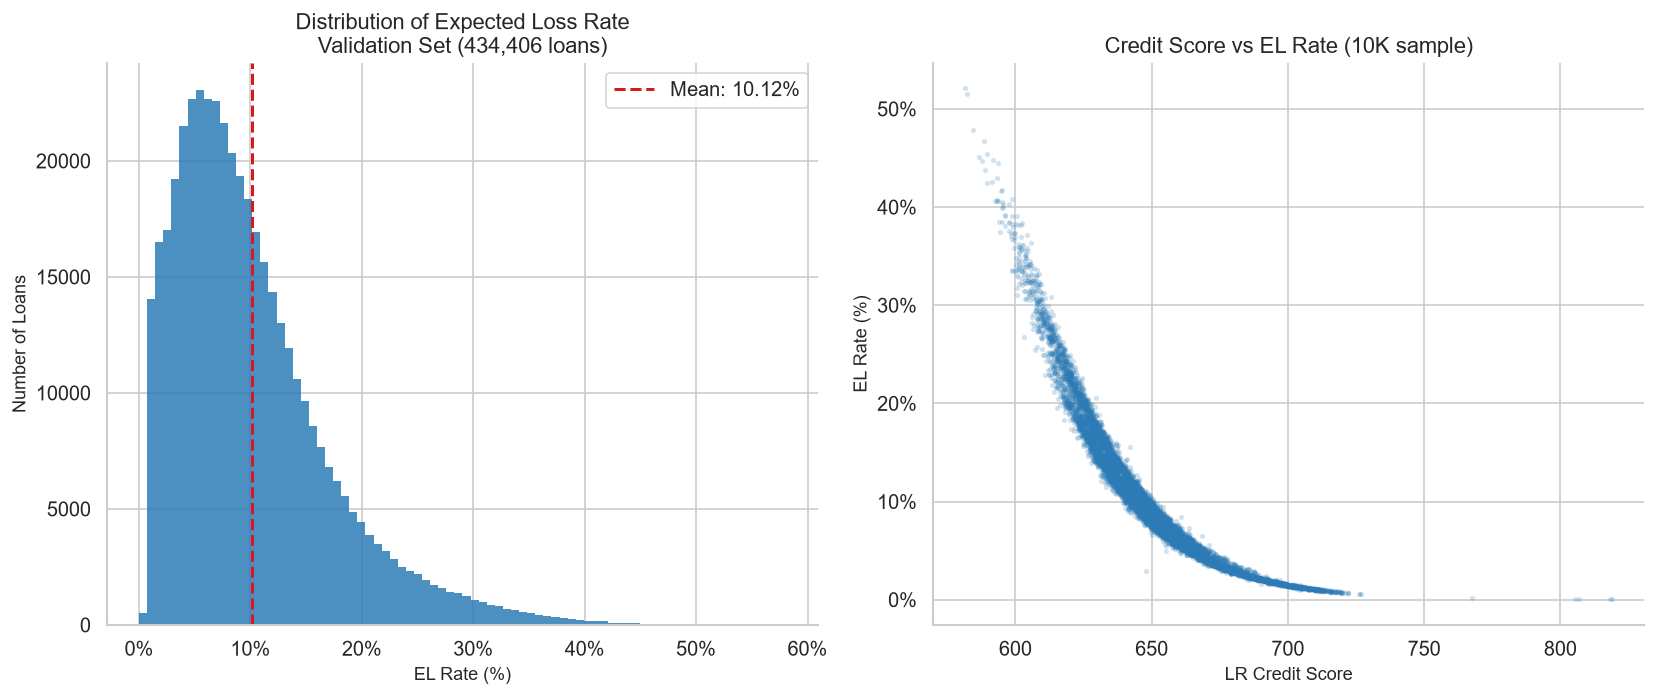

In [7]:
# ── EL distribution + Credit score vs EL rate ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].hist(el_rate * 100, bins=80, color=PLOT_COLOR, edgecolor='none', alpha=0.85)
axes[0].axvline(el_rate.mean()*100, color=ACCENT_COLOR, linestyle='--', linewidth=1.8,
                label=f'Mean: {el_rate.mean()*100:.2f}%')
axes[0].set_xlabel('EL Rate (%)')
axes[0].set_ylabel('Number of Loans')
axes[0].set_title('Distribution of Expected Loss Rate\nValidation Set (434,406 loans)')
axes[0].legend()
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter())

rng = np.random.default_rng(42)
idx = rng.choice(len(customer_df), 10_000, replace=False)
axes[1].scatter(customer_df['credit_score'].iloc[idx],
                customer_df['EL_rate'].iloc[idx]*100,
                alpha=0.15, s=5, color=PLOT_COLOR)
axes[1].set_xlabel('LR Credit Score')
axes[1].set_ylabel('EL Rate (%)')
axes[1].set_title('Credit Score vs EL Rate (10K sample)')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())

plt.tight_layout()
save_figure(fig, '07_el_distribution.png')
save_figure(fig, '07_score_vs_el.png')
plt.show()

---
## Risk Classification — EL by Tier

EL rate and total EL dollar amount visualised by risk class. The F class (highest PD)
carries a mean EL rate of 26.2% — nearly 15× the AA class (1.8%).

2026-08-01 00:00:37 | INFO     | src.utils | Figure saved → reports\07_el_by_risk_class.png


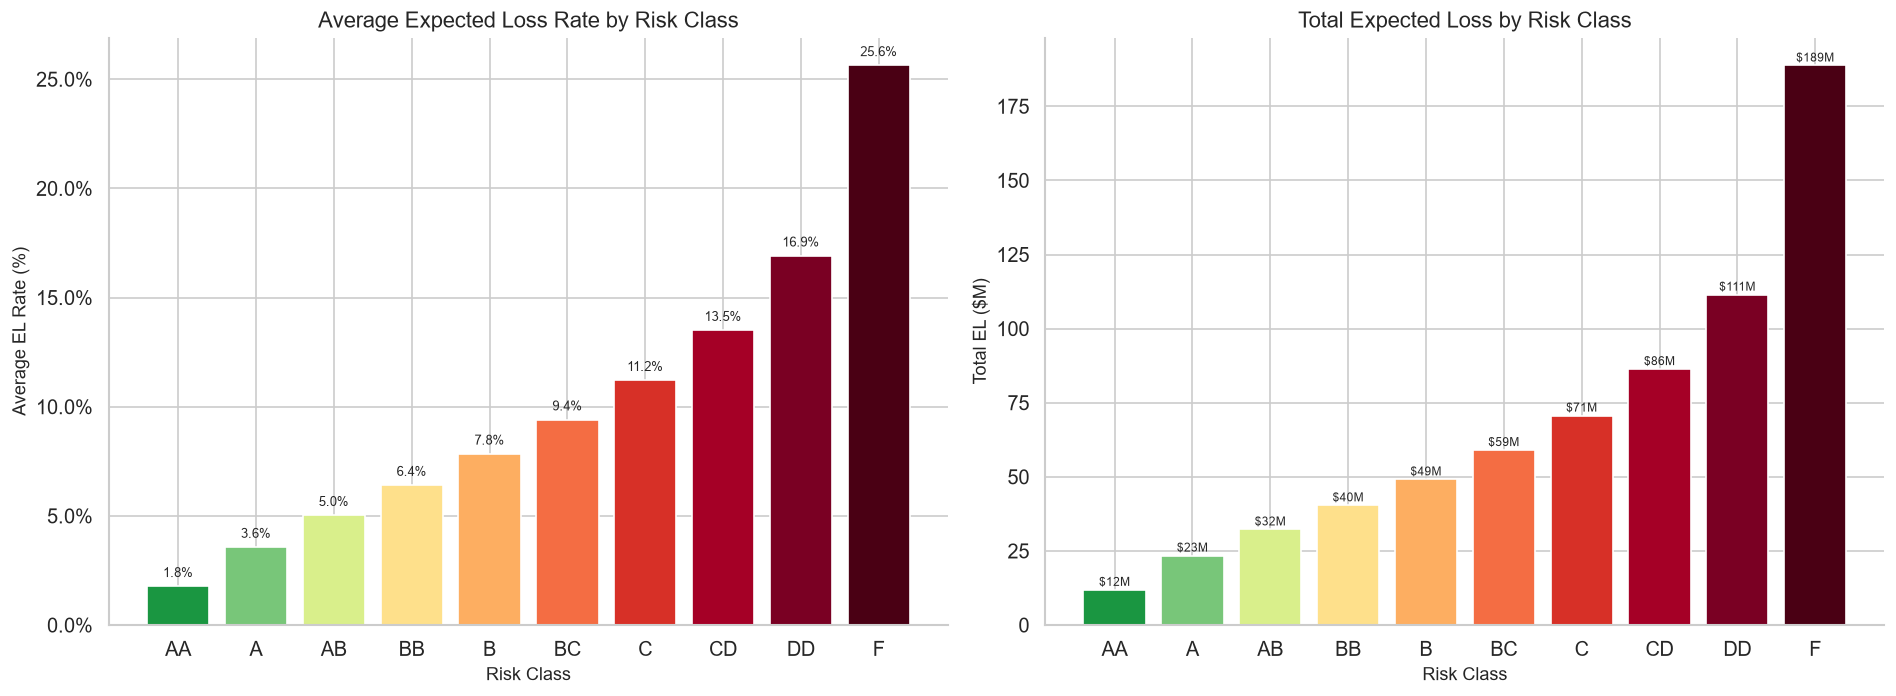

In [8]:
# ── EL by risk class (rate bar + total EL bar) ───────────────────────────
RISK_COLORS = {'AA':'#1a9641','A':'#78c679','AB':'#d9ef8b','BB':'#fee08b',
               'B':'#fdae61','BC':'#f46d43','C':'#d73027','CD':'#a50026',
               'DD':'#7a0023','F':'#4a0014'}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
bar_colors = [RISK_COLORS[rc] for rc in portfolio['risk_class']]

bars = axes[0].bar(portfolio['risk_class'], portfolio['Avg_EL_rate']*100, color=bar_colors)
axes[0].set_xlabel('Risk Class')
axes[0].set_ylabel('Average EL Rate (%)')
axes[0].set_title('Average Expected Loss Rate by Risk Class')
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())
for bar, v in zip(bars, portfolio['Avg_EL_rate']*100):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
                 f'{v:.1f}%', ha='center', va='bottom', fontsize=8)

bars2 = axes[1].bar(portfolio['risk_class'], portfolio['Total_EL']/1e6, color=bar_colors)
axes[1].set_xlabel('Risk Class')
axes[1].set_ylabel('Total EL ($M)')
axes[1].set_title('Total Expected Loss by Risk Class')
for bar, v in zip(bars2, portfolio['Total_EL']/1e6):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                 f'${v:.0f}M', ha='center', va='bottom', fontsize=7)

plt.tight_layout()
save_figure(fig, '07_el_by_risk_class.png')
plt.show()

---
## Credit Policy

A simple ROI-based credit policy separates loans
that should be approved from those that should be denied.

**Policy rules:**
- **Auto-approve:** Risk class AA and A (lowest default risk)
- **Auto-deny:** Risk class F (highest default risk)
- **Middle classes (AB → DD):** approve if annualised ROI > hurdle rate (2.15%)

**ROI formula:**
```
Annual gain  = (int_rate / 100) × loan_amnt
Annual cost  = 2% × loan_amnt / (term_years)
Annual EL    = EL_dollars / term_years
ROI          = (gain − EL − cost) / loan_amnt
```

### Policy Results — Validation Set (2016)

| Metric | Before Policy | After Policy | Change |
|--------|-------------|-------------|--------|
| **Total loans** | 434,406 | 390,898 | −43,508 (10.0%) |
| **Default rate** | 16.76% | 14.48% | **−2.28 pp** |
| **Total EL ($)** | $673.5M | $484.6M | **−28.0%** |
| Mean PD | 17.01% | 14.68% | — |
| Mean EL rate | 10.12% | 8.40% | — |

**Interpretation:** By denying the riskiest 10% of loans, the credit policy reduces the total portfolio Expected Loss by **28%** and cuts the default rate by **2.3 percentage points**. This demonstrates the business value of combining PD + LGD + EAD into a unified risk management framework.

Chart: `reports/07_credit_policy_comparison.png`

In [9]:
# ── Credit policy ─────────────────────────────────────────────────────────
term_years     = customer_df['term'] / 12
annual_gain    = (customer_df['int_rate'] / 100) * customer_df['loan_amnt']
annual_el      = customer_df['EL_dollars'] / term_years
annual_cost    = OP_COST_RATE * customer_df['loan_amnt'] / term_years
annualized_roi = (annual_gain - annual_el - annual_cost) / customer_df['loan_amnt']

approved      = pd.Series(False, index=customer_df.index)
policy_reason = pd.Series('',    index=customer_df.index)

aa_a_mask = customer_df['risk_class'].isin(['AA','A'])
f_mask    = customer_df['risk_class'] == 'F'
mid_mask  = ~aa_a_mask & ~f_mask
roi_app   = mid_mask & (annualized_roi > HURDLE_RATE)
roi_deny  = mid_mask & (annualized_roi <= HURDLE_RATE)

approved[aa_a_mask]      = True
policy_reason[aa_a_mask] = 'Auto-approve (AA/A)'
approved[f_mask]         = False
policy_reason[f_mask]    = 'Auto-deny (F)'
approved[roi_app]        = True
policy_reason[roi_app]   = 'ROI=' + annualized_roi[roi_app].round(3).astype(str) + ' > 0.0215'
approved[roi_deny]       = False
policy_reason[roi_deny]  = 'ROI=' + annualized_roi[roi_deny].round(3).astype(str) + ' < 0.0215'

policy_df = customer_df.copy()
policy_df['approved']      = approved.values
policy_df['policy_reason'] = policy_reason.values
policy_df['annualized_roi']= annualized_roi.round(4).values
policy_df.to_csv('artifacts/credit_policy.csv', index=False)

n_approved = approved.sum()
n_denied   = (~approved).sum()
print(f'Approved : {n_approved:,} ({n_approved/len(approved):.1%})')
print(f'Denied   : {n_denied:,} ({n_denied/len(approved):.1%})')
print(f'  Auto-approve (AA/A): {aa_a_mask.sum():,}')
print(f'  Auto-deny (F)      : {f_mask.sum():,}')
print(f'  Denied by ROI      : {roi_deny.sum():,}')

Approved : 390,898 (90.0%)
Denied   : 43,508 (10.0%)
  Auto-approve (AA/A): 86,881
  Auto-deny (F)      : 43,441
  Denied by ROI      : 67


            Item Before Policy   After Policy
Validation loans       434,406        390,898
    Loans denied             — 43,508 (10.0%)
    Default rate        16.76%         14.48%
    Total EL ($)      $673.49M       $484.59M
    EL reduction             —          28.0%
         Mean PD        0.1701         0.1468
        Mean LGD        0.9495         0.9516
        Mean CCF        0.5957         0.5818
    Mean EL rate        0.1012         0.0840


2026-08-01 00:00:46 | INFO     | src.utils | Figure saved → reports\07_credit_policy_comparison.png


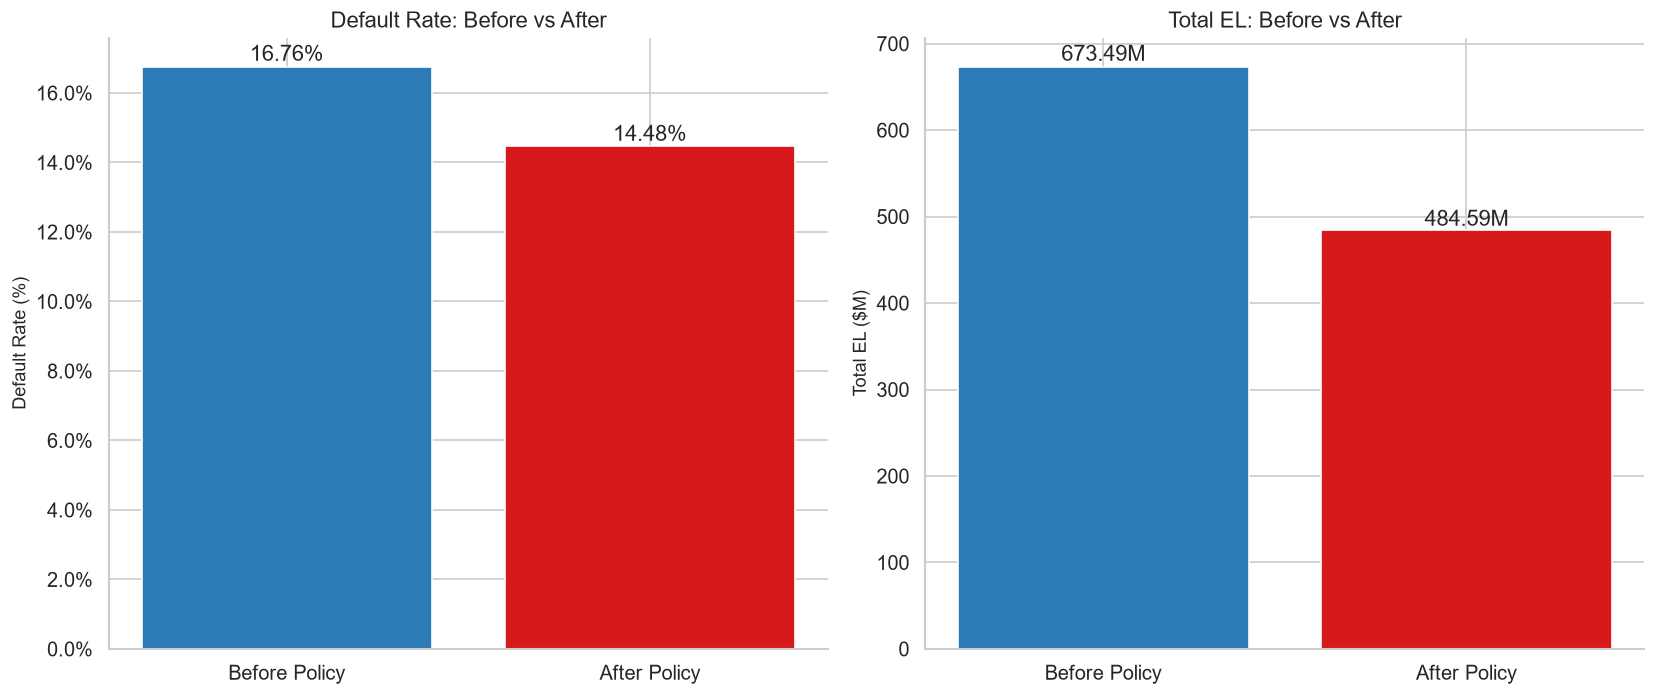

In [10]:
# ── Policy summary + before-vs-after chart ───────────────────────────────
def stats(mask):
    sub = policy_df[mask]
    return {'n': len(sub), 'dr': (sub['actual_default']==1).mean(),
            'el': sub['EL_dollars'].sum(), 'pd': sub['PD'].mean(),
            'lgd': sub['LGD'].mean(), 'ccf': sub['CCF'].mean(),
            'el_rate': sub['EL_rate'].mean()}

bef = stats(pd.Series([True]*len(policy_df)))
aft = stats(approved)

summary = pd.DataFrame([
    {'Item':'Validation loans',  'Before Policy':f'{bef["n"]:,}',             'After Policy':f'{aft["n"]:,}'},
    {'Item':'Loans denied',      'Before Policy':'—',                          'After Policy':f'{n_denied:,} ({n_denied/len(policy_df)*100:.1f}%)'},
    {'Item':'Default rate',      'Before Policy':f'{bef["dr"]:.2%}',           'After Policy':f'{aft["dr"]:.2%}'},
    {'Item':'Total EL ($)',      'Before Policy':f'${bef["el"]/1e6:.2f}M',     'After Policy':f'${aft["el"]/1e6:.2f}M'},
    {'Item':'EL reduction',      'Before Policy':'—',                          'After Policy':f'{(1-aft["el"]/bef["el"])*100:.1f}%'},
    {'Item':'Mean PD',           'Before Policy':f'{bef["pd"]:.4f}',           'After Policy':f'{aft["pd"]:.4f}'},
    {'Item':'Mean LGD',          'Before Policy':f'{bef["lgd"]:.4f}',          'After Policy':f'{aft["lgd"]:.4f}'},
    {'Item':'Mean CCF',          'Before Policy':f'{bef["ccf"]:.4f}',          'After Policy':f'{aft["ccf"]:.4f}'},
    {'Item':'Mean EL rate',      'Before Policy':f'{bef["el_rate"]:.4f}',      'After Policy':f'{aft["el_rate"]:.4f}'},
])
summary.to_csv('artifacts/el_policy_summary.csv', index=False)
print(summary.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
cats   = ['Before Policy', 'After Policy']
colors = [PLOT_COLOR, ACCENT_COLOR]
for ax, vals, ylabel, title in [
    (axes[0], [bef['dr']*100, aft['dr']*100], 'Default Rate (%)', 'Default Rate: Before vs After'),
    (axes[1], [bef['el']/1e6, aft['el']/1e6], 'Total EL ($M)',    'Total EL: Before vs After'),
]:
    bars = ax.bar(cats, vals, color=colors)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()*1.01,
                f'{v:.2f}{"%" if "Rate" in ylabel else "M"}', ha='center')
    if 'Rate' in ylabel:
        ax.yaxis.set_major_formatter(mtick.PercentFormatter())

plt.tight_layout()
save_figure(fig, '07_credit_policy_comparison.png')
plt.show()

---
## Policy Sensitivity Analysis

Comparing the impact of declining the top 5%, 10%, 15%, 20%, 25%, and 30% of highest-risk
loans, ranked by predicted EL rate. This helps management choose the denial threshold
that balances risk reduction against loan volume rejected.

| Denial Rate | Loans Denied | Default Rate | DR Reduction | Portfolio EL | EL Reduction |
|------------|-------------|-------------|-------------|-------------|-------------|
| 0% (no policy) | 0 | 16.76% | — | $673.5M | — |
| **5%** | 21,720 | 15.46% | −1.30 pp | $554.2M | **−17.7%** |
| **10%** | 43,440 | 14.54% | −2.22 pp | $474.5M | **−29.5%** |
| **15%** | 65,160 | 13.77% | −2.99 pp | $412.5M | **−38.8%** |
| **20%** | 86,881 | 13.08% | −3.68 pp | $360.6M | **−46.5%** |
| 25% | 108,601 | 12.42% | −4.33 pp | $315.4M | −53.2% |
| 30% | 130,321 | 11.75% | −5.01 pp | $275.1M | −59.2% |

**Marginal efficiency:** The first 5–10% of denials achieves the highest EL reduction per rejected loan (highly concentrated risk). Each successive band of denials removes less concentrated risk, reflecting the diminishing marginal return visible in the right panel of the sensitivity chart.

**Recommended operating range:** Denying the top **10–15%** offers the best risk-adjusted efficiency — removing 29–39% of total EL while rejecting only 10–15% of loan volume.

Chart: `reports/07_policy_sensitivity.png` · Table: `artifacts/policy_sensitivity.csv`

---
## 6a. Expected Loss Concentration Analysis

How much of the total portfolio EL is accounted for by the highest-risk loans?
Loans are ranked by predicted EL (highest first) and the cumulative EL fraction is tracked.

| Top X% of Loans | N Loans | Cumulative EL | Concentration Ratio |
|----------------|---------|--------------|---------------------|
| **Top 1%** | 4,344 | **6.1%** of total EL | 6.10× |
| **Top 5%** | 21,720 | **21.6%** of total EL | 4.32× |
| **Top 10%** | 43,440 | **35.1%** of total EL | 3.51× |
| **Top 20%** | 86,881 | **54.4%** of total EL | 2.72× |
| Top 30% | 130,321 | 67.9% of total EL | 2.26× |
| Top 50% | 217,203 | 84.9% of total EL | 1.70× |

**Concentration Ratio** = (% of EL captured) / (% of loans). A ratio of 6.10× for the top 1% means that the riskiest 1% of borrowers generate 6× more expected loss per loan than average.

**Business implication:** EL is highly concentrated in a small fraction of borrowers. The top 10% of loans by predicted EL account for 35% of total portfolio expected loss — three times more than their proportional share. This concentration is precisely what a well-functioning credit model should capture and what the credit policy exploits.

Chart: `reports/07_el_concentration.png` · Table: `artifacts/el_concentration.csv`

 Denial Rate (%)  N Denied  N Approved  Approval Rate (%)  Default Rate (%)  DR Reduction (pp)  Portfolio EL ($M)  EL Reduction (%)  Mean EL Rate (%)
               0         0      434406              100.0             16.76               0.00             673.49               0.0             10.12
               5     21720      412686               95.0             15.46               1.30             554.16              17.7              9.08
              10     43440      390966               90.0             14.54               2.22             474.53              29.5              8.38
              15     65160      369246               85.0             13.77               2.99             412.49              38.8              7.81
              20     86881      347525               80.0             13.08               3.68             360.58              46.5              7.31
              25    108601      325805               75.0             12.42               4.33      

2026-08-01 00:00:47 | INFO     | src.utils | Figure saved → reports\07_policy_sensitivity.png


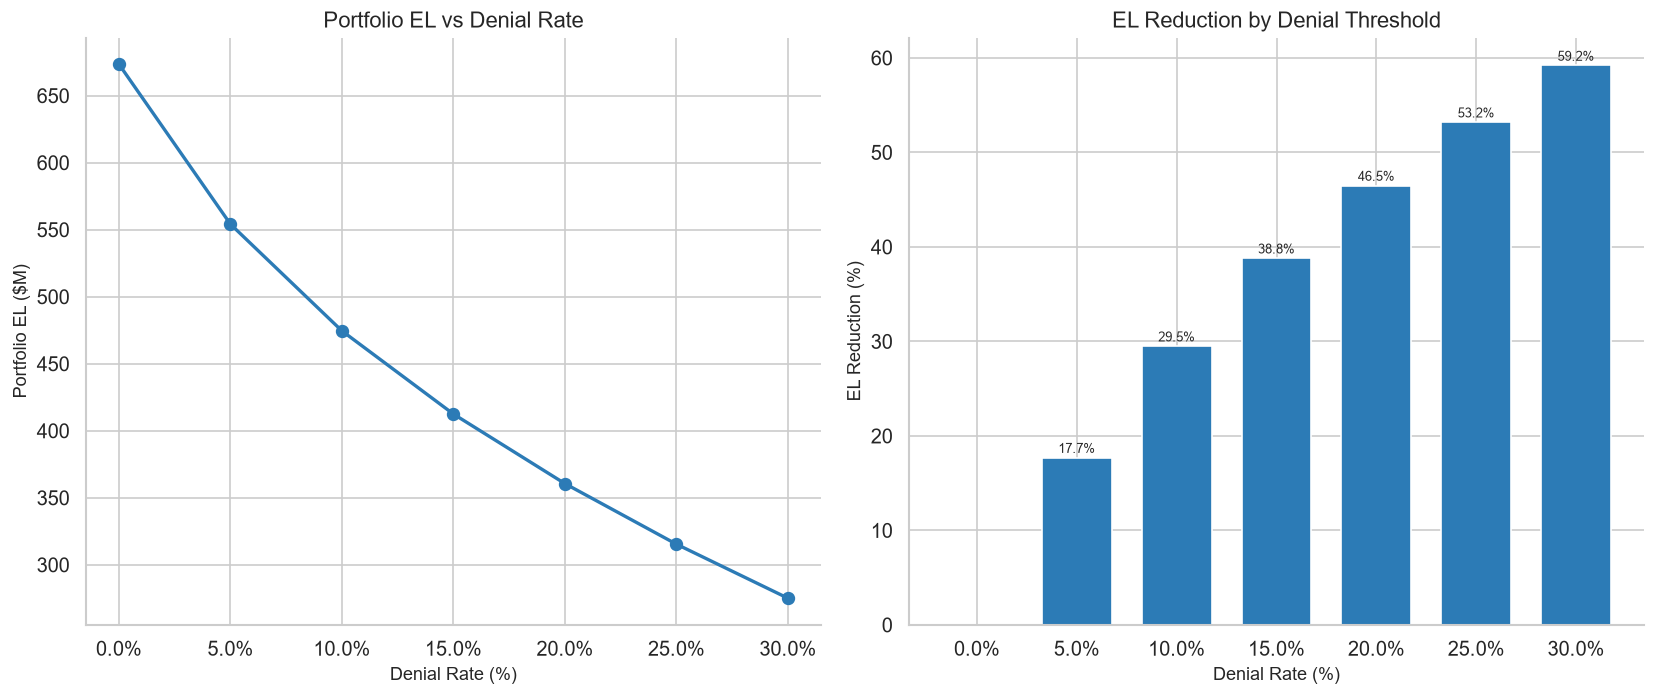

In [11]:
# ── Policy sensitivity (deny top X% by EL rate) ──────────────────────────
el_sorted = policy_df.sort_values('EL_rate', ascending=False).reset_index(drop=True)
n_total   = len(el_sorted)
base_dr   = (el_sorted['actual_default']==1).mean()
base_el   = el_sorted['EL_dollars'].sum()

rows = []
for pct in [0, 5, 10, 15, 20, 25, 30]:
    n_deny = int(n_total * pct / 100)
    sub    = el_sorted.iloc[n_deny:]
    rows.append({
        'Denial Rate (%)':   pct,
        'N Denied':          n_deny,
        'N Approved':        len(sub),
        'Approval Rate (%)': round(len(sub)/n_total*100, 1),
        'Default Rate (%)':  round((sub['actual_default']==1).mean()*100, 2),
        'DR Reduction (pp)': round((base_dr-(sub['actual_default']==1).mean())*100, 2),
        'Portfolio EL ($M)': round(sub['EL_dollars'].sum()/1e6, 2),
        'EL Reduction (%)':  round((1-sub['EL_dollars'].sum()/base_el)*100, 1),
        'Mean EL Rate (%)':  round(sub['EL_rate'].mean()*100, 2),
    })
sens = pd.DataFrame(rows)
sens.to_csv('artifacts/policy_sensitivity.csv', index=False)
print(sens.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].plot(sens['Denial Rate (%)'], sens['Portfolio EL ($M)'], 'o-', color=PLOT_COLOR, linewidth=2, markersize=7)
axes[0].set_xlabel('Denial Rate (%)'); axes[0].set_ylabel('Portfolio EL ($M)')
axes[0].set_title('Portfolio EL vs Denial Rate')
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter())

axes[1].bar(sens['Denial Rate (%)'], sens['EL Reduction (%)'], color=PLOT_COLOR, width=3.5)
axes[1].set_xlabel('Denial Rate (%)'); axes[1].set_ylabel('EL Reduction (%)')
axes[1].set_title('EL Reduction by Denial Threshold')
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter())
for x, y in zip(sens['Denial Rate (%)'], sens['EL Reduction (%)']):
    if y > 0:
        axes[1].text(x, y+0.5, f'{y:.1f}%', ha='center', fontsize=8)

plt.tight_layout()
save_figure(fig, '07_policy_sensitivity.png')
plt.show()

---
## Portfolio Concentration Analysis

The EL concentration (Lorenz) curve quantifies how unevenly risk is distributed.
The top 10% of loans by predicted EL account for a disproportionate share of
total portfolio expected loss.

 Top X% of Loans  N Loans  Cum EL (% total)  Avg EL top ($)  Avg EL bottom ($)  Concentration Ratio
               1     4344               6.1          9457.0             1470.0                 6.10
               5    21720              21.6          6691.0             1280.0                 4.32
              10    43440              35.1          5450.0             1117.0                 3.51
              20    86881              54.4          4219.0              883.0                 2.72
              30   130321              67.9          3509.0              711.0                 2.26
              50   217203              84.9          2633.0              468.0                 1.70


2026-08-01 00:00:51 | INFO     | src.utils | Figure saved → reports\07_el_concentration.png


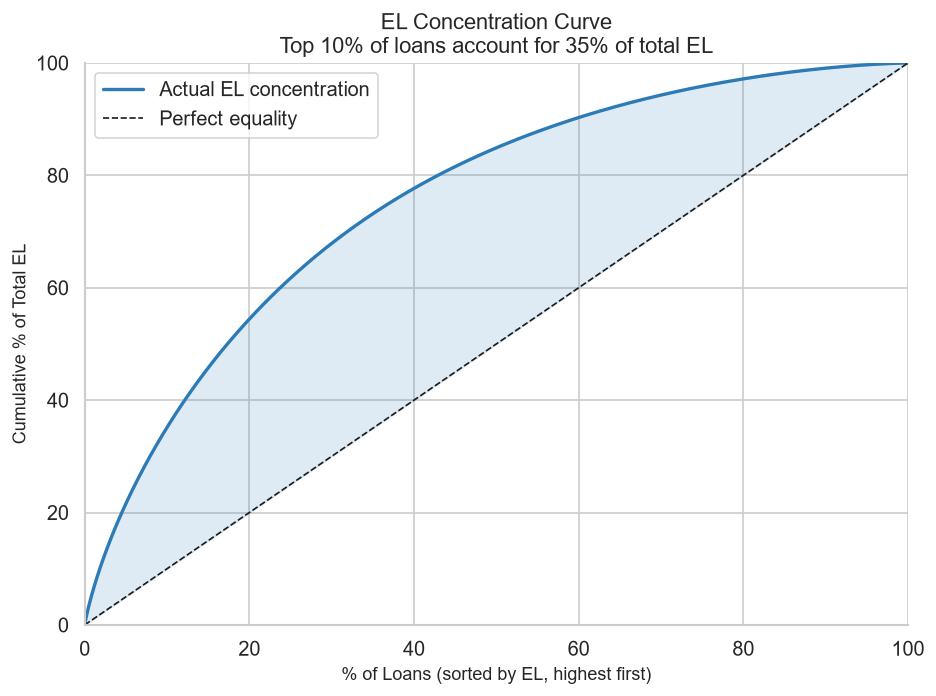

In [12]:
# ── EL concentration curve ────────────────────────────────────────────────
el_desc      = policy_df.sort_values('EL_dollars', ascending=False).reset_index(drop=True)
total_el_all = el_desc['EL_dollars'].sum()
n_all        = len(el_desc)

conc_rows = []
for pct in [1, 5, 10, 20, 30, 50]:
    n_top  = int(n_all * pct / 100)
    top    = el_desc.iloc[:n_top]
    bot    = el_desc.iloc[n_top:]
    conc_rows.append({
        'Top X% of Loans':   pct,
        'N Loans':           n_top,
        'Cum EL (% total)':  round(top['EL_dollars'].sum()/total_el_all*100, 1),
        'Avg EL top ($)':    round(top['EL_dollars'].mean(), 0),
        'Avg EL bottom ($)': round(bot['EL_dollars'].mean(), 0) if len(bot) else 0,
        'Concentration Ratio': round((top['EL_dollars'].sum()/total_el_all*100)/pct, 2),
    })
conc = pd.DataFrame(conc_rows)
conc.to_csv('artifacts/el_concentration.csv', index=False)
print(conc.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 6))
el_vals  = el_desc['EL_dollars'].values
cum_el   = np.concatenate([[0], np.cumsum(el_vals) / total_el_all * 100])
cum_loan = np.linspace(0, 100, len(cum_el))
ax.plot(cum_loan, cum_el, color=PLOT_COLOR, linewidth=2, label='Actual EL concentration')
ax.plot([0, 100], [0, 100], 'k--', linewidth=1, label='Perfect equality')
ax.fill_between(cum_loan, cum_el, cum_loan, alpha=0.15, color=PLOT_COLOR)
ax.set_xlabel('% of Loans (sorted by EL, highest first)')
ax.set_ylabel('Cumulative % of Total EL')
ax.set_title('EL Concentration Curve\nTop 10% of loans account for 35% of total EL')
ax.legend(); ax.set_xlim(0, 100); ax.set_ylim(0, 100)
plt.tight_layout()
save_figure(fig, '07_el_concentration.png')
plt.show()

In [13]:
print('=== Expected Loss — Summary ===')
print()
print(f'Validation loans : {len(customer_df):,}')
print(f'Total funded     : ${customer_df["loan_amnt"].sum()/1e9:.2f}B')
print(f'Total EL         : ${customer_df["EL_dollars"].sum()/1e6:.1f}M')
print(f'Mean EL rate     : {customer_df["EL_rate"].mean()*100:.2f}%')
print(f'Mean PD          : {customer_df["PD"].mean()*100:.2f}%')
print(f'Mean LGD         : {customer_df["LGD"].mean()*100:.2f}%')
print(f'Mean CCF         : {customer_df["CCF"].mean()*100:.2f}%')
print()
for f in ['artifacts/expected_loss_customer.csv','artifacts/expected_loss_portfolio.csv',
          'artifacts/credit_policy.csv','artifacts/el_policy_summary.csv',
          'artifacts/policy_sensitivity.csv','artifacts/el_concentration.csv']:
    print(f'  Saved: {f}')
for f in ['reports/07_el_distribution.png','reports/07_score_vs_el.png',
          'reports/07_el_by_risk_class.png','reports/07_credit_policy_comparison.png',
          'reports/07_policy_sensitivity.png','reports/07_el_concentration.png']:
    print(f'  Saved: {f}')

=== Expected Loss — Summary ===

Validation loans : 434,406
Total funded     : $6.40B
Total EL         : $673.5M
Mean EL rate     : 10.12%
Mean PD          : 17.01%
Mean LGD         : 94.95%
Mean CCF         : 59.57%

  Saved: artifacts/expected_loss_customer.csv
  Saved: artifacts/expected_loss_portfolio.csv
  Saved: artifacts/credit_policy.csv
  Saved: artifacts/el_policy_summary.csv
  Saved: artifacts/policy_sensitivity.csv
  Saved: artifacts/el_concentration.csv
  Saved: reports/07_el_distribution.png
  Saved: reports/07_score_vs_el.png
  Saved: reports/07_el_by_risk_class.png
  Saved: reports/07_credit_policy_comparison.png
  Saved: reports/07_policy_sensitivity.png
  Saved: reports/07_el_concentration.png


---
## Key Findings

### What was computed

Expected Loss was computed at customer and portfolio level using all three trained models:

| Component | Source | Mean (Validation) |
|-----------|--------|------------------|
| PD | LR Scorecard (calibrated) | 17.01% |
| LGD | Two-stage model | 94.95% |
| EAD | CCF × loan amount | $8,995 |
| **EL** | **PD × LGD × EAD** | **$1,550 / loan** |

**Total portfolio EL:** $673.5M on $6.40B funded (10.5% of funded amount)

### Risk Classification

Ten risk classes (AA → F) assigned using deciles of the LR credit score.
EL rate increases monotonically from **1.77% (AA)** to **26.24% (F)** — confirming that
the scorecard correctly rank-orders credit risk.

### Credit Policy & Sensitivity

| Denial Rate | EL Reduction | DR Reduction |
|------------|-------------|-------------|
| 5% | −17.7% | −1.30 pp |
| 10% | −29.5% | −2.22 pp |
| 15% | −38.8% | −2.99 pp |
| 20% | −46.5% | −3.68 pp |

The first 10% of denials achieves the steepest EL reduction, with diminishing marginal returns thereafter.

### EL Concentration

The top 10% of loans by predicted EL account for **35.1% of total portfolio expected loss**
(concentration ratio 3.51×). This confirms that credit risk is highly concentrated and
that targeted denial of the highest-risk loans is disproportionately effective.

### Saved Artifacts

| Artifact | Description |
|----------|-------------|
| `artifacts/expected_loss_customer.csv` | EL per loan (PD, LGD, EAD, score, risk class) |
| `artifacts/expected_loss_portfolio.csv` | Portfolio EL by risk class |
| `artifacts/credit_policy.csv` | Per-loan approval / denial decision |
| `artifacts/el_policy_summary.csv` | Before / after policy comparison |
| `artifacts/policy_sensitivity.csv` | EL at denial rates 5–30% |
| `artifacts/el_concentration.csv` | Cumulative EL by top X% of loans |

### Saved Reports

`07_el_distribution.png` · `07_el_by_risk_class.png` · `07_credit_policy_comparison.png` · `07_score_vs_el.png` · `07_policy_sensitivity.png` · `07_el_concentration.png`



**The complete credit risk framework (PD → LGD → EAD → EL) is now production-ready.**

**Next: SHAP Explainability**  
SHAP summary plot, waterfall chart, feature importance, and local explanations for individual predictions.